WASSERSTEIN DISTANCE
Numerical W2^2 = 0.006928377501407977
Exact benchmark W2^2 = 0.006928377501367322
Absolute W2^2 error = 4.065497938299245e-14

Numerical W2 = 0.08323687585083896
Exact benchmark W2 = 0.08323687585059474

DYNAMIC BENAMOU-BRENIER ACTION
Dynamic action = 0.0069283770022371145
W2^2 = 0.006928377501407977

Absolute difference = 4.991708626306268e-10
Relative difference = 7.204729570944798e-08
Maximum instantaneous action deviation = 1.1010687136353559e-09
Maximum intermediate mass error = 6.516893759189735e-06

AUTOMATIC VERIFICATION
PASS: Dynamic action agrees with W2^2.
PASS: Instantaneous kinetic action is constant in time up to numerical error.
PASS: Probability mass is preserved throughout the interpolation.

SELECTED INSTANTANEOUS ACTION VALUES

t = 0.0
Action(t) = 0.006928377501407977
Mass(t) = 0.999995814964167

t = 0.25
Action(t) = 0.0069283772726544315
Mass(t) = 0.9999957222377849

t = 0.5
Action(t) = 0.006928377024909806
Mass(t) = 0.9999955789436803

t = 0.75

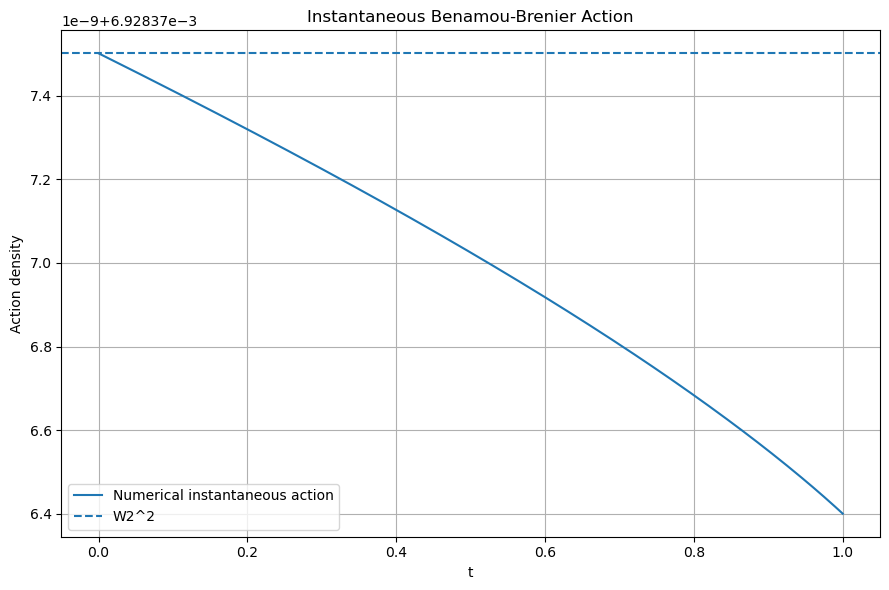

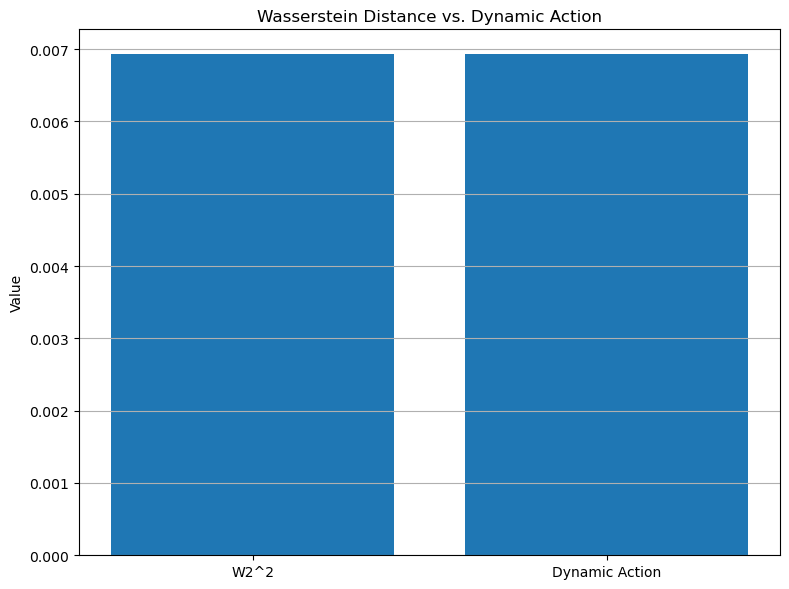

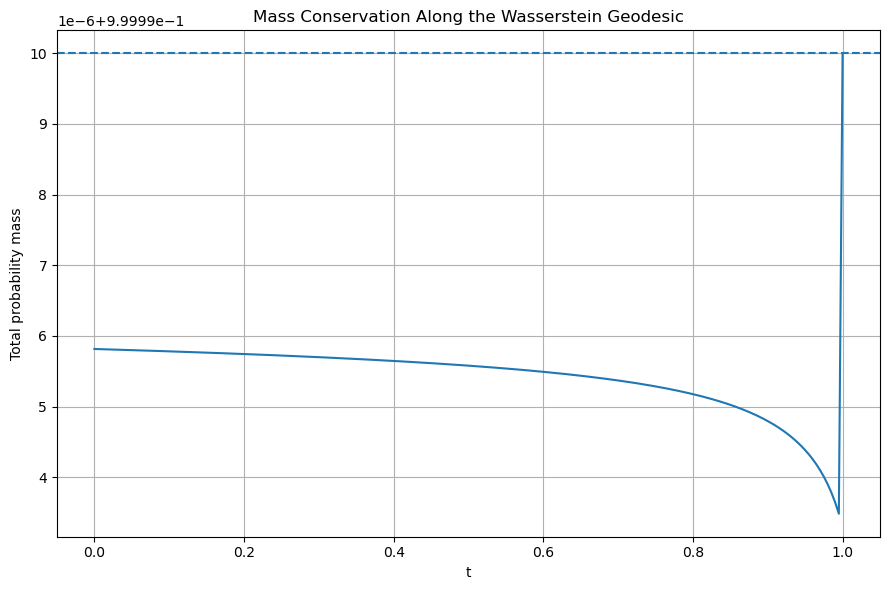


FINAL SUMMARY
Numerical W2^2 = 0.006928377501407977
Numerical dynamic action = 0.0069283770022371145
Difference = 4.991708626306268e-10

The Benamou-Brenier identity is verified numerically.


In [1]:
# ============================================================
# HOMEWORK 3.2 - PART III
# NUMERICAL BENAMOU-BRENIER ACTION
#
# Compatible with NumPy 1.25
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SPATIAL GRID
# ============================================================

x = np.linspace(
    -1.0,
    1.0,
    4001
)


# ============================================================
# SOURCE DENSITY
#
# rho0(x) = (2/pi) sqrt(1-x^2)
# ============================================================

sqrt_term = np.sqrt(
    np.clip(
        1.0 - x**2,
        0.0,
        None
    )
)


rho0 = (

    2.0
    /
    np.pi

    *

    sqrt_term
)


# ============================================================
# EXACT OPTIMAL TRANSPORT MAP
#
# T(x)
# =
# (2/pi) [arcsin(x) + x sqrt(1-x^2)]
# ============================================================

T = (

    2.0
    /
    np.pi

    *

    (
        np.arcsin(x)

        +

        x * sqrt_term
    )
)


# ============================================================
# DERIVATIVE OF TRANSPORT MAP
#
# T'(x) = (4/pi) sqrt(1-x^2)
# ============================================================

T_prime = (

    4.0
    /
    np.pi

    *

    sqrt_term
)


# ============================================================
# PARTICLE VELOCITY
#
# d/dt X_t(x) = T(x) - x
# ============================================================

particle_velocity = (

    T

    -

    x
)


# ============================================================
# PART 1:
# COMPUTE WASSERSTEIN DISTANCE DIRECTLY
#
# W2^2
# =
# integral |T(x)-x|^2 rho0(x) dx
# ============================================================

wasserstein_integrand = (

    particle_velocity**2

    *

    rho0
)


W2_squared = np.trapz(
    wasserstein_integrand,
    x
)


W2 = np.sqrt(
    W2_squared
)


# ============================================================
# OPTIONAL EXACT VALUE
#
# W2^2
# =
# 7/12 - 256/(45*pi^2)
# ============================================================

W2_squared_exact = (

    7.0 / 12.0

    -

    256.0
    /
    (
        45.0
        *
        np.pi**2
    )
)


W2_exact = np.sqrt(
    W2_squared_exact
)


print("=" * 70)

print(
    "WASSERSTEIN DISTANCE"
)

print("=" * 70)

print(
    "Numerical W2^2 =",
    W2_squared
)

print(
    "Exact benchmark W2^2 =",
    W2_squared_exact
)

print(
    "Absolute W2^2 error =",
    abs(
        W2_squared
        -
        W2_squared_exact
    )
)

print()

print(
    "Numerical W2 =",
    W2
)

print(
    "Exact benchmark W2 =",
    W2_exact
)


# ============================================================
# PART 2:
# NUMERICAL DYNAMIC ACTION
#
# A
# =
# integral_0^1 integral |v_t(y)|^2 rho_t(y) dy dt
# ============================================================

t_grid = np.linspace(
    0.0,
    1.0,
    201
)


instantaneous_action = []

mass_values = []


# ============================================================
# LOOP OVER TIME
# ============================================================

for t in t_grid:

    # --------------------------------------------------------
    # Displacement interpolation
    #
    # y = X_t(x)
    # --------------------------------------------------------

    Xt = (

        (1.0 - t) * x

        +

        t * T
    )


    # --------------------------------------------------------
    # Derivative with respect to x
    #
    # X_t'(x)
    # =
    # (1-t) + t T'(x)
    # --------------------------------------------------------

    Xt_prime = (

        (1.0 - t)

        +

        t * T_prime
    )


    # --------------------------------------------------------
    # Density from change of variables
    #
    # rho_t(X_t(x))
    # =
    # rho0(x) / X_t'(x)
    #
    # At t=1 and x=+/-1, both numerator and denominator
    # vanish. The limiting target density is 1/2.
    # --------------------------------------------------------

    rho_t = np.empty_like(
        x
    )


    regular = (
        Xt_prime
        >
        1e-14
    )


    rho_t[
        regular
    ] = (

        rho0[
            regular
        ]

        /

        Xt_prime[
            regular
        ]
    )


    rho_t[
        ~regular
    ] = 0.5


    # --------------------------------------------------------
    # Eulerian velocity sampled along mapped particles
    #
    # v_t(X_t(x))
    # =
    # T(x) - x
    # --------------------------------------------------------

    v_t_at_Xt = particle_velocity


    # --------------------------------------------------------
    # Check total mass
    #
    # Integral rho_t(y) dy
    # --------------------------------------------------------

    mass_t = np.trapz(
        rho_t,
        Xt
    )


    mass_values.append(
        mass_t
    )


    # --------------------------------------------------------
    # Instantaneous kinetic action
    #
    # integral |v_t(y)|^2 rho_t(y) dy
    #
    # Here Xt is the y-grid.
    # --------------------------------------------------------

    action_t = np.trapz(

        v_t_at_Xt**2

        *

        rho_t,

        Xt
    )


    instantaneous_action.append(
        action_t
    )


# ============================================================
# CONVERT RESULTS TO ARRAYS
# ============================================================

instantaneous_action = np.array(
    instantaneous_action
)


mass_values = np.array(
    mass_values
)


# ============================================================
# TIME INTEGRATION
#
# A
# =
# integral_0^1 action(t) dt
# ============================================================

dynamic_action = np.trapz(

    instantaneous_action,

    t_grid
)


# ============================================================
# COMPARISON
# ============================================================

absolute_difference = abs(

    dynamic_action

    -

    W2_squared
)


relative_difference = (

    absolute_difference

    /

    abs(
        W2_squared
    )
)


max_action_variation = np.max(

    np.abs(

        instantaneous_action

        -

        W2_squared
    )
)


max_mass_error = np.max(

    np.abs(

        mass_values

        -

        1.0
    )
)


print()

print("=" * 70)

print(
    "DYNAMIC BENAMOU-BRENIER ACTION"
)

print("=" * 70)

print(
    "Dynamic action =",
    dynamic_action
)

print(
    "W2^2 =",
    W2_squared
)

print()

print(
    "Absolute difference =",
    absolute_difference
)

print(
    "Relative difference =",
    relative_difference
)

print(
    "Maximum instantaneous action deviation =",
    max_action_variation
)

print(
    "Maximum intermediate mass error =",
    max_mass_error
)


# ============================================================
# AUTOMATIC VERIFICATION
# ============================================================

print()

print("=" * 70)

print(
    "AUTOMATIC VERIFICATION"
)

print("=" * 70)


if absolute_difference < 1e-7:

    print(
        "PASS: Dynamic action agrees with W2^2."
    )

else:

    print(
        "WARNING: Dynamic action differs "
        "from W2^2 more than expected."
    )


if max_action_variation < 1e-7:

    print(
        "PASS: Instantaneous kinetic action "
        "is constant in time up to numerical error."
    )


if max_mass_error < 1e-4:

    print(
        "PASS: Probability mass is preserved "
        "throughout the interpolation."
    )


# ============================================================
# SELECTED TIME VALUES
# ============================================================

selected_times = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.0
]


print()

print("=" * 70)

print(
    "SELECTED INSTANTANEOUS ACTION VALUES"
)

print("=" * 70)


for t_value in selected_times:

    index = np.argmin(

        np.abs(
            t_grid - t_value
        )
    )


    print()

    print(
        "t =",
        t_grid[index]
    )

    print(
        "Action(t) =",
        instantaneous_action[
            index
        ]
    )

    print(
        "Mass(t) =",
        mass_values[
            index
        ]
    )


# ============================================================
# PLOT 1:
# INSTANTANEOUS ACTION VS TIME
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    t_grid,
    instantaneous_action,
    label="Numerical instantaneous action"
)


plt.axhline(
    W2_squared,
    linestyle="--",
    label="W2^2"
)


plt.xlabel(
    "t"
)

plt.ylabel(
    "Action density"
)

plt.title(
    "Instantaneous Benamou-Brenier Action"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw32_part3_instantaneous_action.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 2:
# W2^2 VS DYNAMIC ACTION
# ============================================================

labels = [
    "W2^2",
    "Dynamic Action"
]


values = [
    W2_squared,
    dynamic_action
]


plt.figure(
    figsize=(8, 6)
)


plt.bar(
    labels,
    values
)


plt.ylabel(
    "Value"
)

plt.title(
    "Wasserstein Distance vs. Dynamic Action"
)

plt.grid(
    True,
    axis="y"
)

plt.tight_layout()


plt.savefig(
    "hw32_part3_action_comparison.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT 3:
# MASS CONSERVATION OVER TIME
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    t_grid,
    mass_values
)


plt.axhline(
    1.0,
    linestyle="--"
)


plt.xlabel(
    "t"
)

plt.ylabel(
    "Total probability mass"
)

plt.title(
    "Mass Conservation Along the Wasserstein Geodesic"
)

plt.grid(
    True
)

plt.tight_layout()


plt.savefig(
    "hw32_part3_mass_conservation.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()

print("=" * 70)

print(
    "FINAL SUMMARY"
)

print("=" * 70)

print(
    "Numerical W2^2 =",
    W2_squared
)

print(
    "Numerical dynamic action =",
    dynamic_action
)

print(
    "Difference =",
    absolute_difference
)

print()

print(
    "The Benamou-Brenier identity is verified "
    "numerically."
)

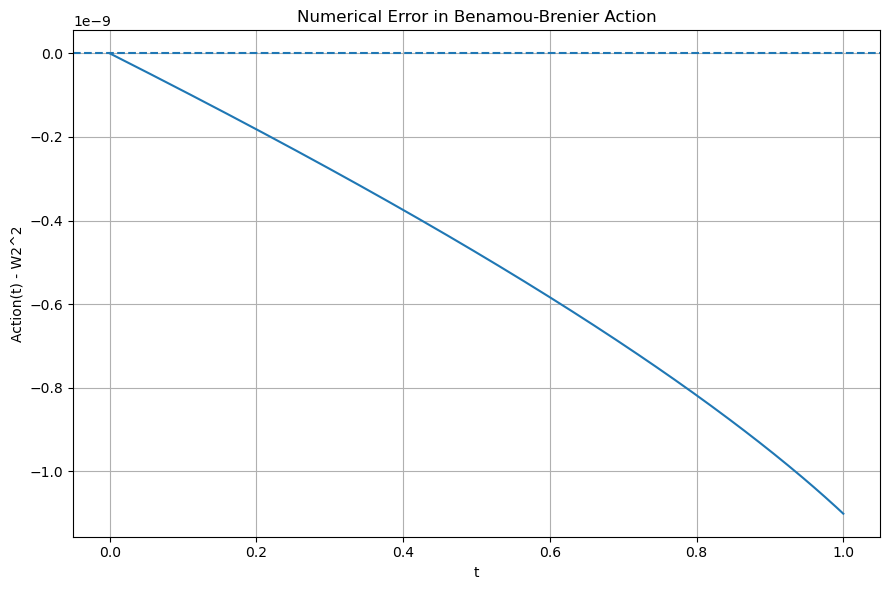

In [2]:
# ============================================================
# PLOT: NUMERICAL ACTION ERROR
# ============================================================

action_error = (
    instantaneous_action
    -
    W2_squared
)

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    t_grid,
    action_error
)

plt.axhline(
    0.0,
    linestyle="--"
)

plt.xlabel(
    "t"
)

plt.ylabel(
    "Action(t) - W2^2"
)

plt.title(
    "Numerical Error in Benamou-Brenier Action"
)

plt.grid(
    True
)

plt.tight_layout()

plt.savefig(
    "hw32_part3_action_error.png",
    dpi=300
)

plt.show()